# 01 — Données : consommation et renouvelables en Allemagne (ENTSO-E)

**Mini-projet Séries Temporelles — Data Science & IA** · rentré du 12/10/2026

| | |
|---|---|
| Fréquence | Horaire (60 min), timestamps UTC |
| Période | 2015-01-01 → 2020-09-30 (5,75 ans) |
| Variables | `Load`, `Wind`, `Solar` (MW) |
| Source | ENTSO-E Transparency via Open Power System Data |

**Reproductibilité** : seed fixée (`123`), aucune donnée - par - ci, aucun
chemin en dur. La logique de chargement vit dans `Python/data_preparation.py`.


In [1]:
# Versions exactes de l'environnement (à reporter dans le rapport)
import sys, numpy, pandas, scipy
print("Python :", sys.version.split()[0])
print("pandas :", pandas.__version__)
print("numpy  :", numpy.__version__)
print("scipy  :", scipy.__version__)

# Seed fixée pour toute réproducibilité (déjà : pas de tirage aléatoire en section 1)
SEED = 123


Python : 3.13.2
pandas : 2.3.3
numpy  : 2.3.3
scipy  : 1.16.2


## Chargement : objet série temporelle natif

`load_germany_series()` retourne un `DataFrame` pandas avec un
`DatetimeIndex` UTC et une **fréquence déclarée `h`**. C'est le seul point
de vérité utilisé par tous les notebooks du projet (cohérence garantie).

In [2]:
from pathlib import Path
import sys

# Localisation robuste de la racine du projet (notebook ouvert depuis notebooks/ ou racine)
ROOT = Path.cwd()
if not (ROOT / "Python").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "Python"))

from data_preparation import load_germany_series, chronological_split

df = load_germany_series()

print("Dimensions :", df.shape)
print("\nIndex :", df.index.name, "| type :", type(df.index).__name__)
print("Fréquence déclarée :", df.index.freq)
print("Début :", df.index.min())
print("Fin   :", df.index.max())
df.head()


Dimensions : (50400, 3)

Index : DateTime | type : DatetimeIndex
Fréquence déclarée : <Hour>
Début : 2015-01-01 00:00:00+00:00
Fin   : 2020-09-30 23:00:00+00:00


,Load,Wind,Solar
DateTime,,,
2015-01-01 00:00:00+00:00,41151,8852.0,NaN
2015-01-01 01:00:00+00:00,40135,9054.0,NaN
2015-01-01 02:00:00+00:00,39106,9070.0,NaN
2015-01-01 03:00:00+00:00,38765,9163.0,NaN
2015-01-01 04:00:00+00:00,38941,9231.0,NaN


In [3]:
df.tail()


,Load,Wind,Solar
DateTime,,,
2020-09-30 19:00:00+00:00,57559,10654.0,0.0
2020-09-30 20:00:00+00:00,54108,11836.0,0.0
2020-09-30 21:00:00+00:00,49845,12168.0,0.0
2020-09-30 22:00:00+00:00,46886,12533.0,0.0
2020-09-30 23:00:00+00:00,45461,12798.0,0.0


## Contrôles qualité

1. **Continuité** : la grille horaire théorique entre début et fin doit
   coïncider exactement avec les timestamps présents (**0 trou**).
2. **Doublons** : un même timestamp ne doit apparaître qu'une fois.
3. **Manquants** : comptés par variable (conservés ici, traités plus tard).

In [4]:
import pandas as pd

# Grille horaire théorique complète
expected = pd.date_range(df.index.min(), df.index.max(), freq="h", tz="UTC")
holes = expected.difference(df.index)
print("Créneaux horaires attendus :", len(expected))
print("Créneaux présents          :", df.index.nunique())
print("Trous (heures manquantes)  :", len(holes))
print("Doublons                   :", df.index.duplicated().sum())

na = df.isna().sum()
print("\nValeurs manquantes par variable :")
print(na.to_string())


Créneaux horaires attendus : 50400
Créneaux présents          : 50400
Trous (heures manquantes)  : 0
Doublons                   : 0

Valeurs manquantes par variable :
Load       0
Wind      74
Solar    103


In [5]:
# Sauvegarde du résumé de qualité (utilisé aussi par le rapport)
summary = pd.DataFrame({
    "n_obs": len(df),
    "start": df.index.min(),
    "end": df.index.max(),
    "freq": str(df.index.freq),
    "n_holes": len(holes),
    "n_duplicates": int(df.index.duplicated().sum()),
    "na_load": int(na["Load"]),
    "na_wind": int(na["Wind"]),
    "na_solar": int(na["Solar"]),
}, index=[0])
out = ROOT / "results" / "tables" / "data_overview_summary.csv"
out.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(out, index=False)
print("Résumé enregistré :", out)


Résumé enregistré : c:\Users\Ons\Documents\TimeSeries_Project\results\tables\data_overview_summary.csv


## Découpage chronologique 90 % / 10 %

En séries temporelles le split est **chronologique, jamais aléatoire**
(un tirage aléatoire ferait fuiter l'information future dans le train).

In [6]:
n = len(df)
n_train = int(round(0.90 * n))
print(f"Train : {n_train} obs ({df.index[n_train-1]})")
print(f"Test  : {n - n_train} obs ({df.index[n_train]} -> {df.index[-1]})")

train, test = chronological_split(df, 0.90)
assert len(train) + len(test) == n
assert train.index[-1] < test.index[0]
print("Split chronologique OK (aucun chevauchement temporel).")


Train : 45360 obs (2020-03-04 23:00:00+00:00)
Test  : 5040 obs (2020-03-05 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00)
Split chronologique OK (aucun chevauchement temporel).


## Bilan de la section 1

- Objet natif créé : `DatetimeIndex` UTC, `freq='h'`.
- 50 400 heures, **0 trou**, **0 doublon** (2015-01-01 → 2020-09-30).
- NA : `Wind` 74, `Solar` 103, `Load` 0 — heures isolées, non traitées ici.
- Split 90/10 chronologique effectué et validé.
- Détail, sources et justifications : `reports/01_donnees.md`.

Aucune transformation statistique appliquée : elle sera décidée par
l'EDA (section 2).


# 02 — Analyse exploratoire (EDA) : énergie allemande horaire

**Mini-projet Séries Temporelles — Data Science & IA** · source : ENTSO-E (Open Power System Data)

Objectifs de la section : visualiser tendance / saisonnalité / ruptures,
interpréter les ACF/PACF, décomposer la série, détecter les valeurs
aberrantes avec traitement justifié, et conclure sur l'ordre de
différenciation via les tests **ADF + KPSS**.

> À retenir du contexte (section 1) : 50 400 h (2015–2020-09-30), 0 trou,
> `Wind` 74 NA, `Solar` 103 NA (heures isolées, non traitées ici),
> split chronologique 90/10 fixé au 2020-03-05 00:00. Le jeu de test
> débute donc en pleine période COVID — point de vigilance.

In [7]:
# Versions exactes de l'environnement
import sys, numpy, pandas, scipy
import statsmodels, matplotlib
print("Python    :", sys.version.split()[0])
print("pandas    :", pandas.__version__)
print("numpy     :", numpy.__version__)
print("scipy     :", scipy.__version__)
print("statsmodels:", statsmodels.__version__)
print("matplotlib:", matplotlib.__version__)

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 123
np.random.seed(SEED)


Python    : 3.13.2
pandas    : 2.3.3
numpy     : 2.3.3
scipy     : 1.16.2
statsmodels: 0.15.0
matplotlib: 3.10.8


In [8]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "Python").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "Python"))
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

from data_preparation import load_germany_series, chronological_split
df = load_germany_series()
train, test = chronological_split(df, 0.90)
SPLIT_DATE = test.index.min()
print("Serie chargee :", df.shape)
print("Split train/test :", train.index[-1], "->", SPLIT_DATE)


Serie chargee : (50400, 3)
Split train/test : 2020-03-04 23:00:00+00:00 -> 2020-03-05 00:00:00+00:00


## 1. Statistiques descriptives

Comptées **avant** interpolation (les NA de Wind/Solar restent inchangés).
On calcule aussi **skewness et kurtosis** : ces statistiques seront
envoyées au LLM en section 5 pour générer des hypothèses de modélisation.

In [9]:
from scipy.stats import skew, kurtosis

desc = df.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].copy()
desc["skew"] = [skew(df[v].dropna()) for v in df.columns]
desc["kurtosis"] = [kurtosis(df[v].dropna()) for v in df.columns]
desc = desc.rename(columns={"25%": "q1", "50%": "mediane", "75%": "q3"})
desc.to_csv(TAB / "descriptive_statistics_py.csv")
print(desc.round(1).to_string())

na_serie = df.isna().sum()
print("\nNA par variable :\n", na_serie.to_string())


          mean      std      min       q1  mediane       q3      max  skew  kurtosis
Load   55492.5  10015.4  31307.0  47106.0  55092.0  64309.2  77549.0  -0.0      -1.1
Wind   11552.2   9076.4    135.0   4506.0   9015.0  16113.8  46064.0   1.1       0.8
Solar   4566.0   6940.3      0.0      0.0    173.0   7342.0  32947.0   1.5       1.4

NA par variable :
 Load       0
Wind      74
Solar    103


### Lecture
- **Load** : moyenne ≈ 55 490 MW, dispersion ≈ 10 015 MW, **symétrique**
  (skew ≈ 0) et à queue moins épaisse que la normale (kurt < 0, distribution
  aplatie). Les extrêmes sont rares : `min` ≈ 31 300, `max` ≈ 77 500.
- **Wind** : moyenne ≈ 11 550, **forte skewness 1,14** (asymétrie à gauche)
  — l'éolien passe beaucoup d'heures à faible production, avec des pointes
  rares (max 46 064).
- **Solar** : moyenne ≈ 4 570 mais **médiane ≈ 173** : la production
  solaire est nulle la moitié du temps (nuit). Cas structurel d'une
  série à **zéros par nature** (skew 1,54) — un vrai défi pour SARIMA pur.

## 2. Visualisation : tendance, saisonnalité, ruptures

Le graphique superpose les trois séries brutes et marque la frontière
**train / test** (début de la période COVID).

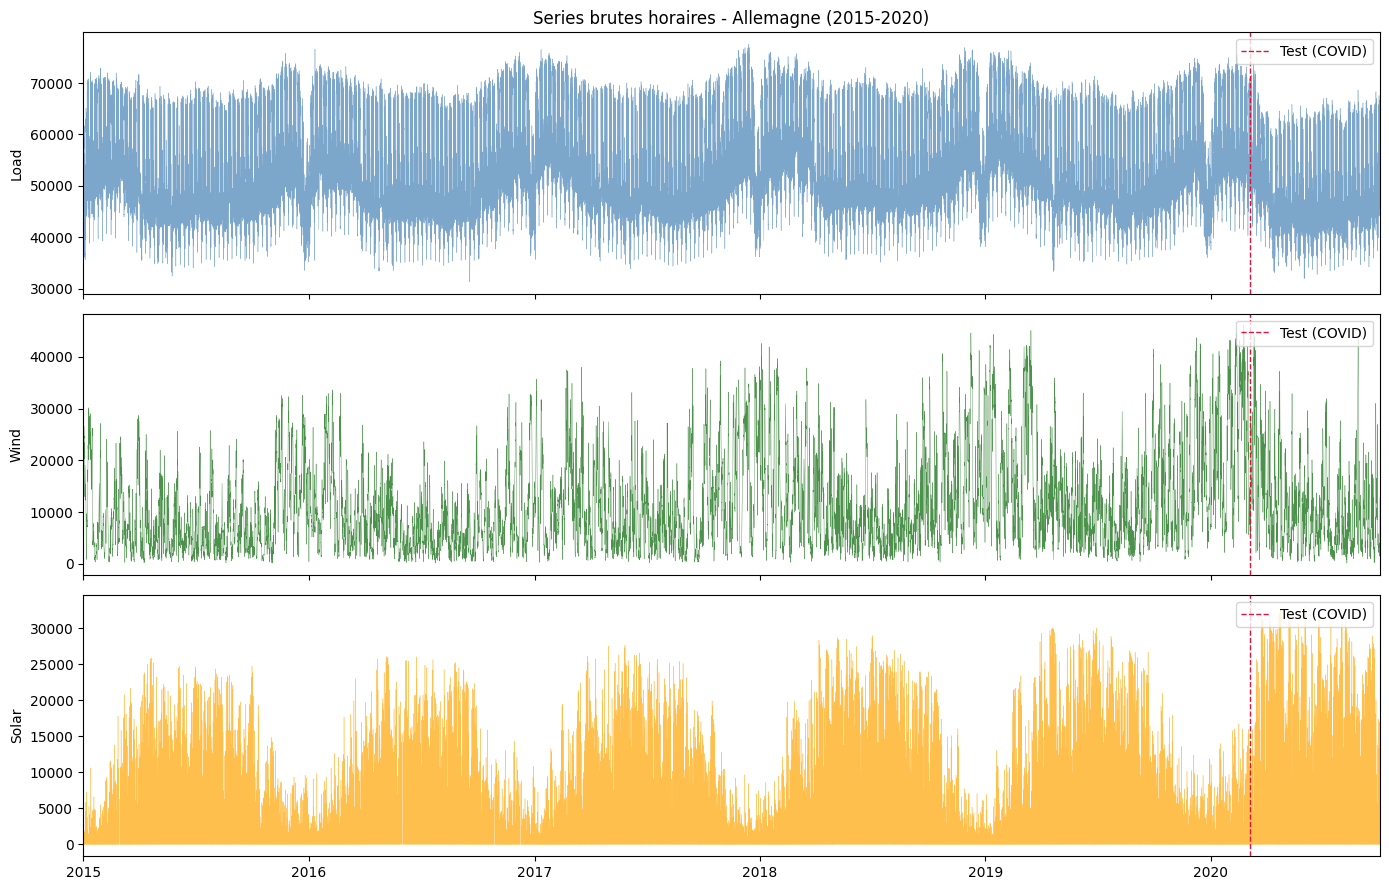

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, v, c in zip(axes, ["Load", "Wind", "Solar"], ["steelblue", "darkgreen", "orange"]):
    ax.plot(df.index, df[v], color=c, linewidth=0.3, alpha=0.7)
    ax.axvline(SPLIT_DATE, color="crimson", linestyle="--", linewidth=1, label="Test (COVID)")
    ax.set_ylabel(v)
    ax.legend(loc="upper right")
    ax.set_xlim(df.index.min(), df.index.max())
axes[0].set_title("Series brutes horaires - Allemagne (2015-2020)")
fig.tight_layout()
fig.savefig(FIG / "py_ts_overview.png", dpi=150)
plt.show()


### Observations
- **Load** : forte **saisonnalité jour/nuit** et **hiver/été** ; structure
  stable sur 5 ans, l'écrasement du pic de consommation dans le test
  (COVID, et surtout les mois d'été/mi-saison) sera à surveiller.
- **Wind** : aucune structure périodique claire, série très « chahutée »
  (rafales météo), niveau moyen plus élevé l'hiver (voir profils.
- **Solar** : cycle quotidien strict (nul la nuit), **saisonnalité annuelle**
  marquée (été >> hiver). Les ruptures visibles du graphique correspondent
  à des NA isolés (heures éparses) et non à des valeurs aberrantes.

## 3. Profils saisonniers (heure, semaine, mois, année)

On agrège par moyenne pour faire ressortir chaque cycle.

--- hour ---
              Load     Wind    Solar
DateTime                           
0         43882.0  11884.3      0.0
1         43553.0  11736.5      0.0
2         44133.7  11640.1      0.3
3         45950.0  11588.5     41.7
4         50131.5  11536.6    426.9
5         55042.1  11337.0   1688.1
6         58897.6  10926.7   4081.7
7         60921.2  10670.2   7253.8
8         62353.5  10676.4  10471.9
9         63640.8  10913.8  12925.4
10        63733.8  11170.8  14278.5
11        62800.9  11359.2  14482.8
12        61518.2  11451.2  13595.2
13        60384.3  11493.7  11661.4
14        59498.6  11515.1   8850.4
15        59599.0  11556.3   5666.0
16        60662.5  11587.9   2868.9
17        60974.8  11634.6   1039.0
18        59544.6  11783.2    226.7
19        56794.2  12079.8     12.3
20        54039.9  12257.7      0.9
21        50915.9  12240.0      0.9
22        47596.1  12177.7      0.0
23        45251.1  12036.5      0.0 

--- week ---
              Load     Wind   Solar

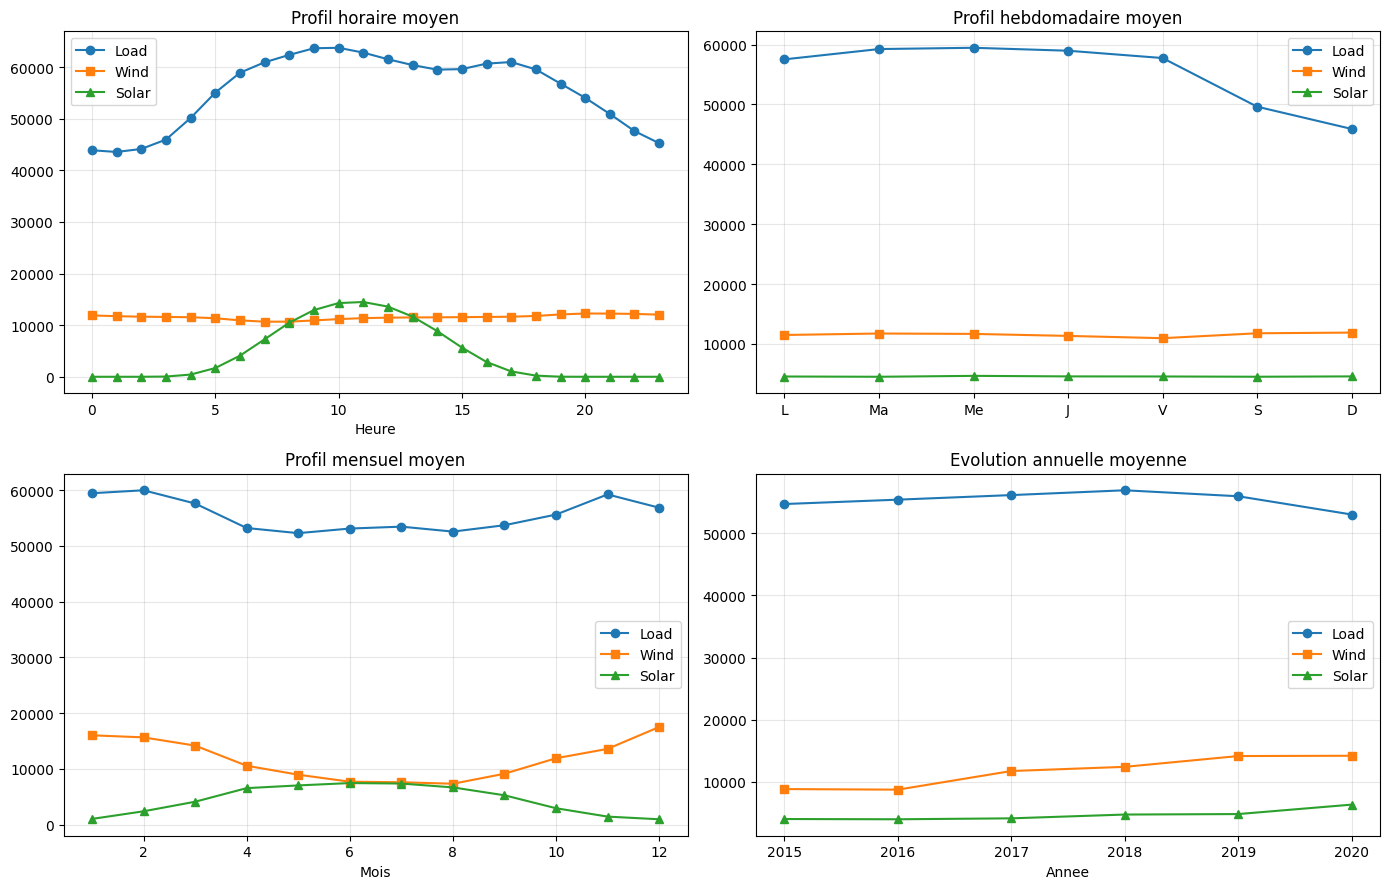

In [11]:
profiles = {
    "hour": df.groupby(df.index.hour)[["Load", "Wind", "Solar"]].mean(),
    "week": df.groupby(df.index.dayofweek)[["Load", "Wind", "Solar"]].mean(),
    "month": df.groupby(df.index.month)[["Load", "Wind", "Solar"]].mean(),
    "year": df.groupby(df.index.year)[["Load", "Wind", "Solar"]].mean(),
}
for name, tab in profiles.items():
    tab.round(1).to_csv(TAB / f"profiles_{name}_py.csv")
    print(f"--- {name} ---\n", tab.round(1).to_string(), "\n")

# Visualisation
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0,0].plot(profiles["hour"].index, profiles["hour"]["Load"], "o-", label="Load")
axes[0,0].plot(profiles["hour"].index, profiles["hour"]["Wind"], "s-", label="Wind")
axes[0,0].plot(profiles["hour"].index, profiles["hour"]["Solar"], "^-", label="Solar")
axes[0,0].set_title("Profil horaire moyen"); axes[0,0].set_xlabel("Heure")

labels_w = ["L", "Ma", "Me", "J", "V", "S", "D"]
axes[0,1].plot(profiles["week"].index, profiles["week"]["Load"], "o-", label="Load")
axes[0,1].plot(profiles["week"].index, profiles["week"]["Wind"], "s-", label="Wind")
axes[0,1].plot(profiles["week"].index, profiles["week"]["Solar"], "^-", label="Solar")
axes[0,1].set_title("Profil hebdomadaire moyen"); axes[0,1].set_xticks(range(7)); axes[0,1].set_xticklabels(labels_w)

axes[1,0].plot(profiles["month"].index, profiles["month"]["Load"], "o-", label="Load")
axes[1,0].plot(profiles["month"].index, profiles["month"]["Wind"], "s-", label="Wind")
axes[1,0].plot(profiles["month"].index, profiles["month"]["Solar"], "^-", label="Solar")
axes[1,0].set_title("Profil mensuel moyen"); axes[1,0].set_xlabel("Mois")

axes[1,1].plot(profiles["year"].index, profiles["year"]["Load"], "o-", label="Load")
axes[1,1].plot(profiles["year"].index, profiles["year"]["Wind"], "s-", label="Wind")
axes[1,1].plot(profiles["year"].index, profiles["year"]["Solar"], "^-", label="Solar")
axes[1,1].set_title("Evolution annuelle moyenne"); axes[1,1].set_xlabel("Annee")

for ax in axes.flat:
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "py_seasonal_profiles.png", dpi=150)
plt.show()


### Lecture
- **Horaire** : Load en **double bosse** — pic du matin (9–11 h ≈ 63,5-63,7 k MW)
  et pic du soir (17 h ≈ 61 k MW) ; creux la nuit (1 h ≈ 43,6 k). Wind est
  presque plat (légèrement plus productif la nuit), Solar nul avant 5 h et
  après 20 h, max de 12-13 h.
- **Hebdomadaire** : week-end moins chargé pour Load (activité industrielle)
  ; Wind et Solar sans effet jour de semaine notable.
- **Mensuel** : Load **hiver > été** (fév. ≈ 60 k c. mai ≈ 52 k) ; Wind
  hiver >> été (déc.-janv. ≈ 17,5-16 k c. juin-juil. ≈ 7,4-7,6 k) ; Solar
  été >> hiver (juin-juil. ≈ 7,4 k c. déc.-janv. ≈ 1 k).
- **Annuel** : pas de tendance monotone franche du Load (légère variation),
  cohérent avec un parc renouvelable en croissance mais une consommation globalement stable.

## 4. Valeurs manquantes dans le temps

On visualise quand les 74 + 103 heures manquantes apparaissent et si elles
se concentrent (ce qui changerait leur traitement).

Heures avec au moins une valeur manquante : 105
NA par mois (max pour diagnostic de cluster) :
count    69.00
mean      1.52
std       5.52
min       0.00
25%       0.00
50%       0.00
75%       0.00
max      24.00


C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\1916618473.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_na = df.assign(mois=df.index.to_period("M"))[["Load", "Wind", "Solar"]].isna().groupby(df.index.to_period("M")).sum()
C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\1916618473.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_na = df.assign(mois=df.index.to_period("M"))[["Load", "Wind", "Solar"]].isna().groupby(df.index.to_period("M")).sum()


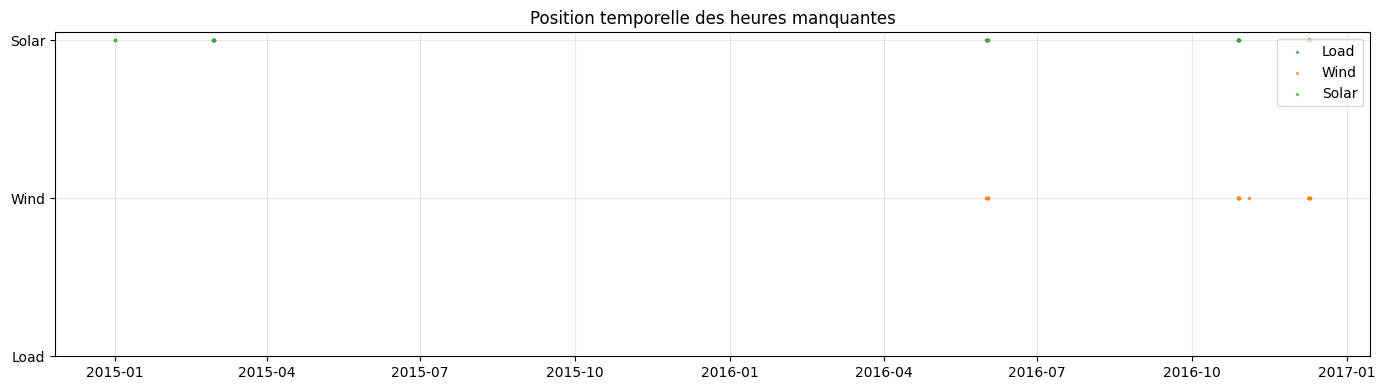

In [12]:
import matplotlib.ticker as mticker
miss = df.isna()
idx_miss = miss.any(axis=1)
print("Heures avec au moins une valeur manquante :", int(idx_miss.sum()))

# Répartition par mois pour vérifier s'il y a des clusters
monthly_na = df.assign(mois=df.index.to_period("M"))[["Load", "Wind", "Solar"]].isna().groupby(df.index.to_period("M")).sum()
print("NA par mois (max pour diagnostic de cluster) :")
print(monthly_na.max(axis=1).describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(14, 4))
for i, v in enumerate(["Load", "Wind", "Solar"]):
    y = df.index[miss[v]]
    ax.scatter(y, np.full(len(y), i), s=2, label=v, alpha=0.6)
ax.set_yticks(range(3)); ax.set_yticklabels(["Load", "Wind", "Solar"])
ax.set_title("Position temporelle des heures manquantes")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "py_missing.png", dpi=150); plt.show()


### Lecture et décision
Les NA sont **isolés** (jamais de bloc de plusieurs jours ; la plupart des
mois ≤ 2 valeurs). Ils sont donc conservés NA et seront interpolés **au
moment de la modélisation** — une interpolation précoce fausserait l'EDA.
C'est la règle : ne jamais deviner une donnée avant l'analyse.

## 5. ACF / PACF sur séries brutes

L'ACF mesure la corrélation avec les valeurs passées. Pour de la donnée
horaire on regarde les lags clés : 1 (heure précédente), 24 (même heure la
veille), 48 (2 jours), ***168 (même heure la semaine précédente)***.

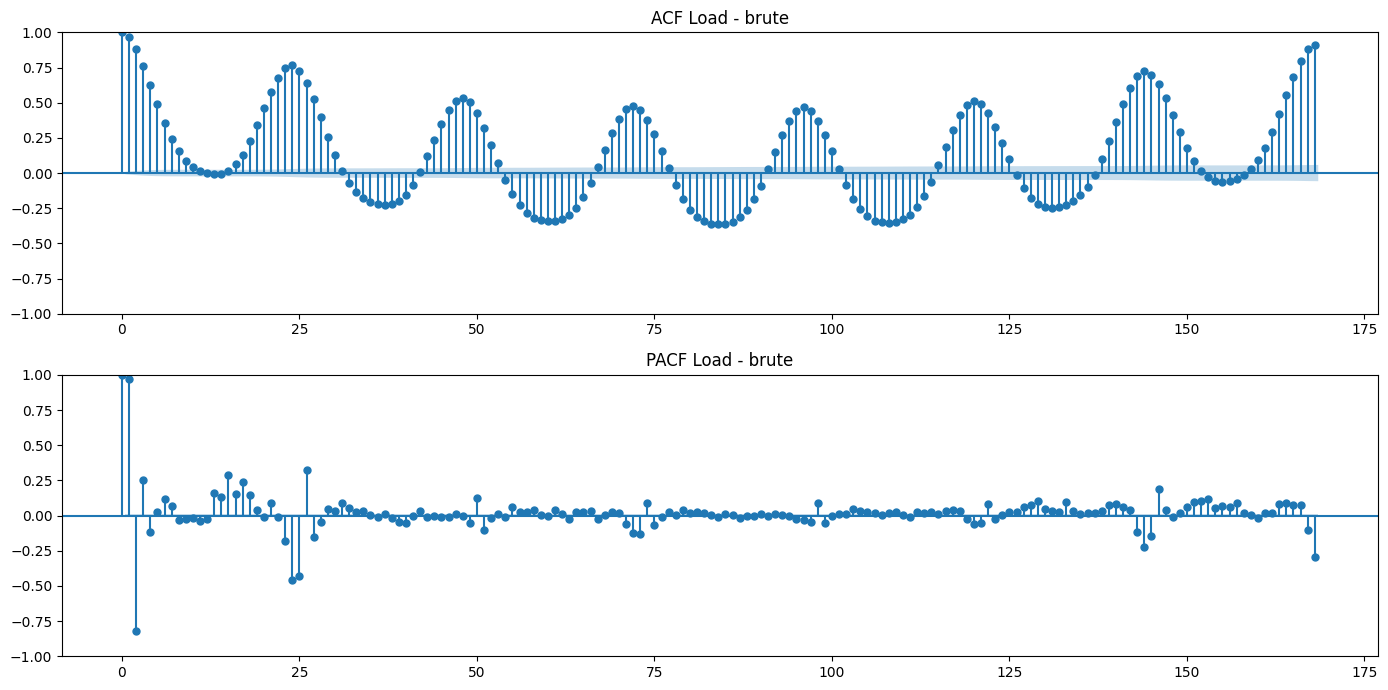

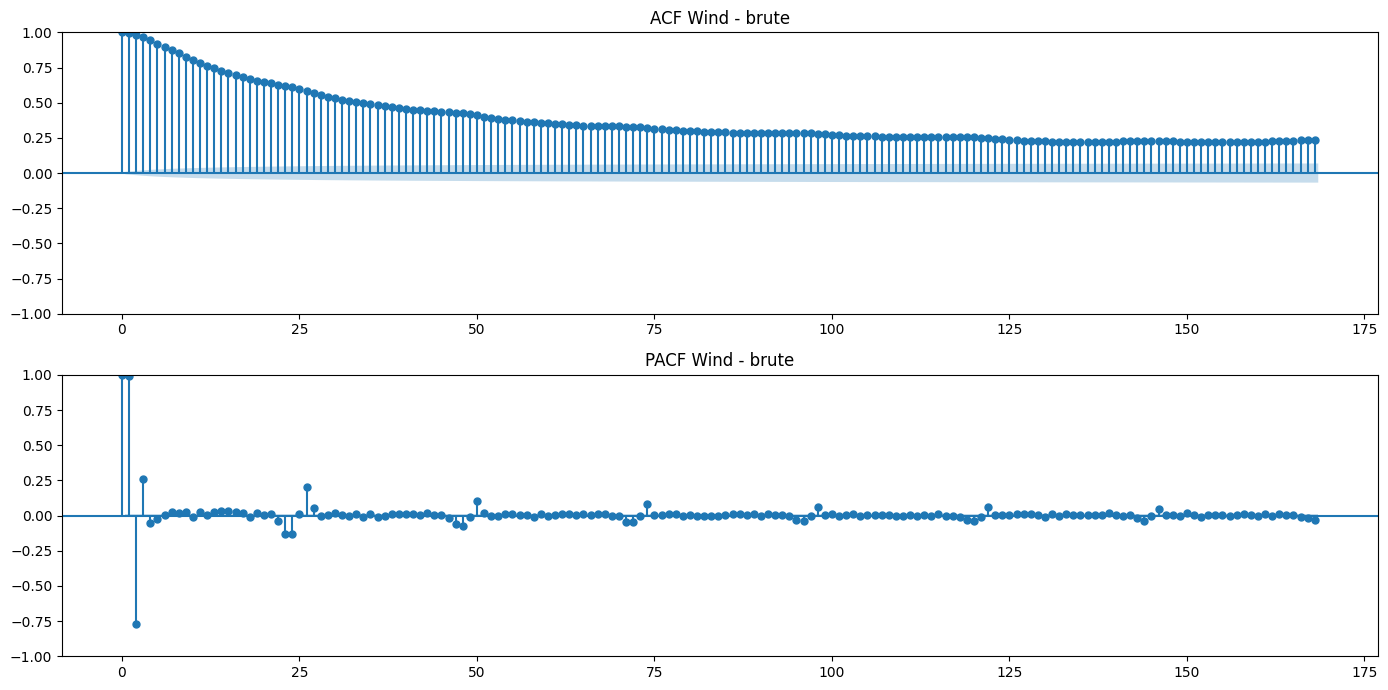

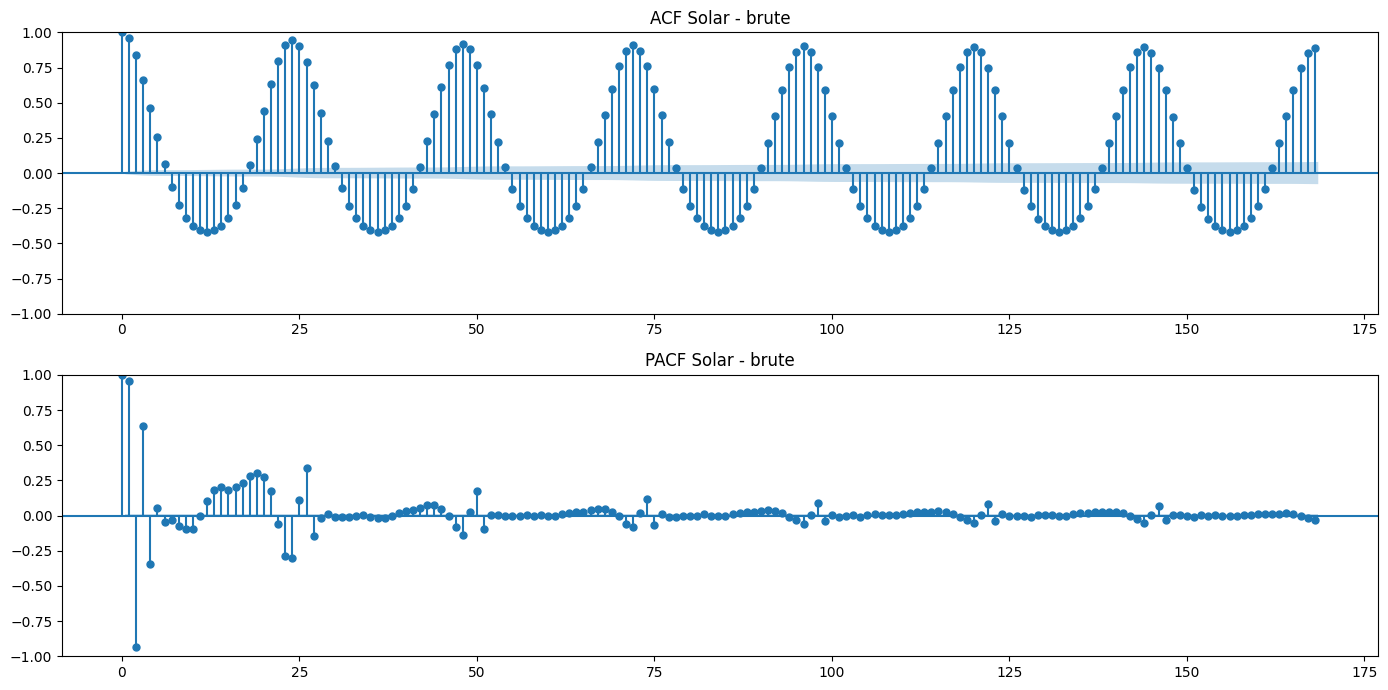

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

LAG = 168
for v in ["Load", "Wind", "Solar"]:
    s = df[v].dropna()
    fig, axes = plt.subplots(2, 1, figsize=(14, 7))
    plot_acf(s, lags=LAG, ax=axes[0], title=f"ACF {v} - brute")
    plot_pacf(s, lags=LAG, ax=axes[1], title=f"PACF {v} - brute")
    fig.tight_layout()
    fig.savefig(FIG / f"py_acf_pacf_{v}_raw.png", dpi=120)
    plt.show()


### ACF mesurées (lags 1, 24, 48, 168) — série brute

| Variable | lag 1 | lag 24 | lag 48 | lag 168 |
|---|---|---|---|---|
| Load | 0,97 | 0,76 | 0,53 | 0,91 |
| Wind | 1,00 | 0,61 | 0,42 | 0,23 |
| Solar | 0,96 | 0,95 | 0,92 | 0,89 |

- **Load** : ACF très élevée, qui **rebondit à chaque multiple de 24**
  (0,76 / 0,53) et surtout à **168 (0,91)** → double saisonnalité
  **quotidienne et hebdomadaire**. La PACF tronque rapidement mais garde
  des pics significatifs aux lags 24 et 168.
- **Wind** : ACF qui **décroît lentement** (effet « long-range » de la
  météo), cycles à 24 présents mais faibles (0,61 → 0,23 à 168). Série peu
  saisonnière, forte persistance de court terme.
- **Solar** : ACF quasi non décroissante avec **sommets à 24/48/168
  (> 0,89)** : saisonnalité quotidienne extrêmement marquée (zéros la
  nuit) → la différenciation simple ne suffira pas, il faudra une
  **différenciation saisonnière**.


## 6. ACF / PACF après différenciation

On teste deux transformations sur **Load** (la variable cible principale) :
- `d1` = différence d'ordre 1 (X_t − X_{t-1}) → traite la non-stationnarité de niveau ;
- `d24` = différence saisonnière de retard 24 (X_t − X_{t-24}) → retranche le cycle quotidien.

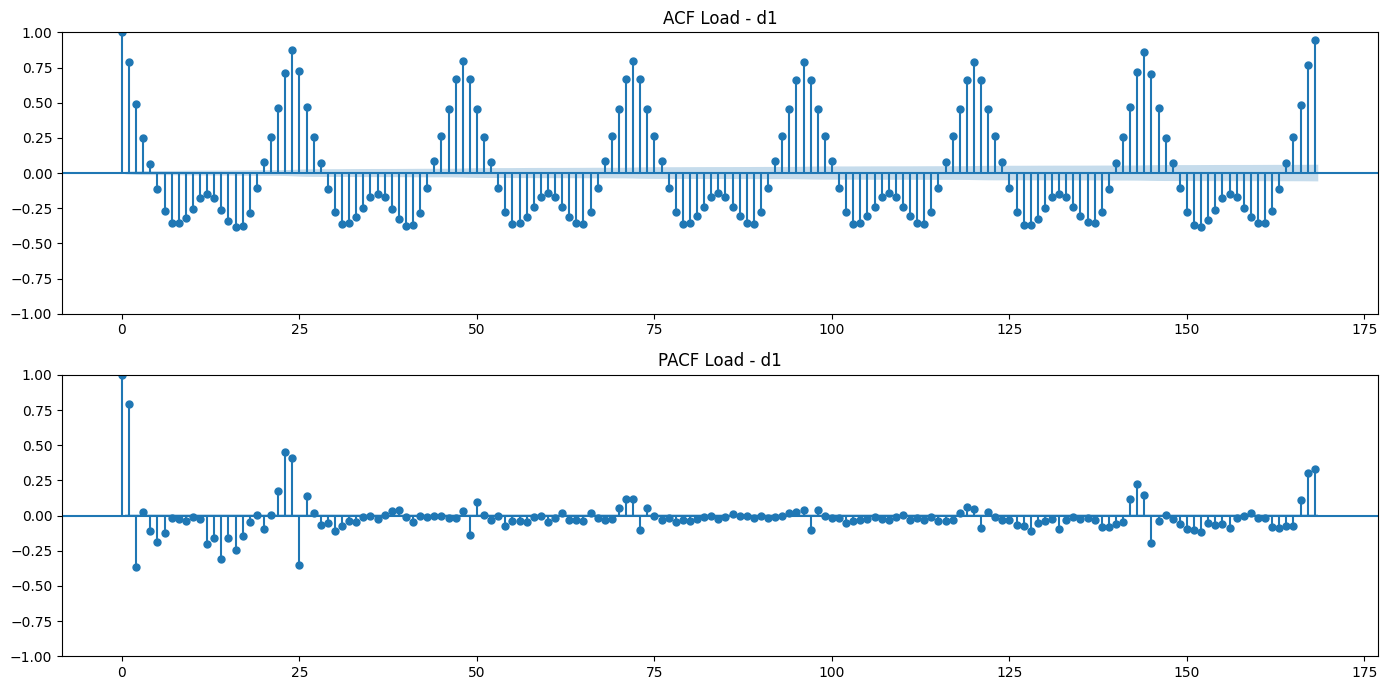

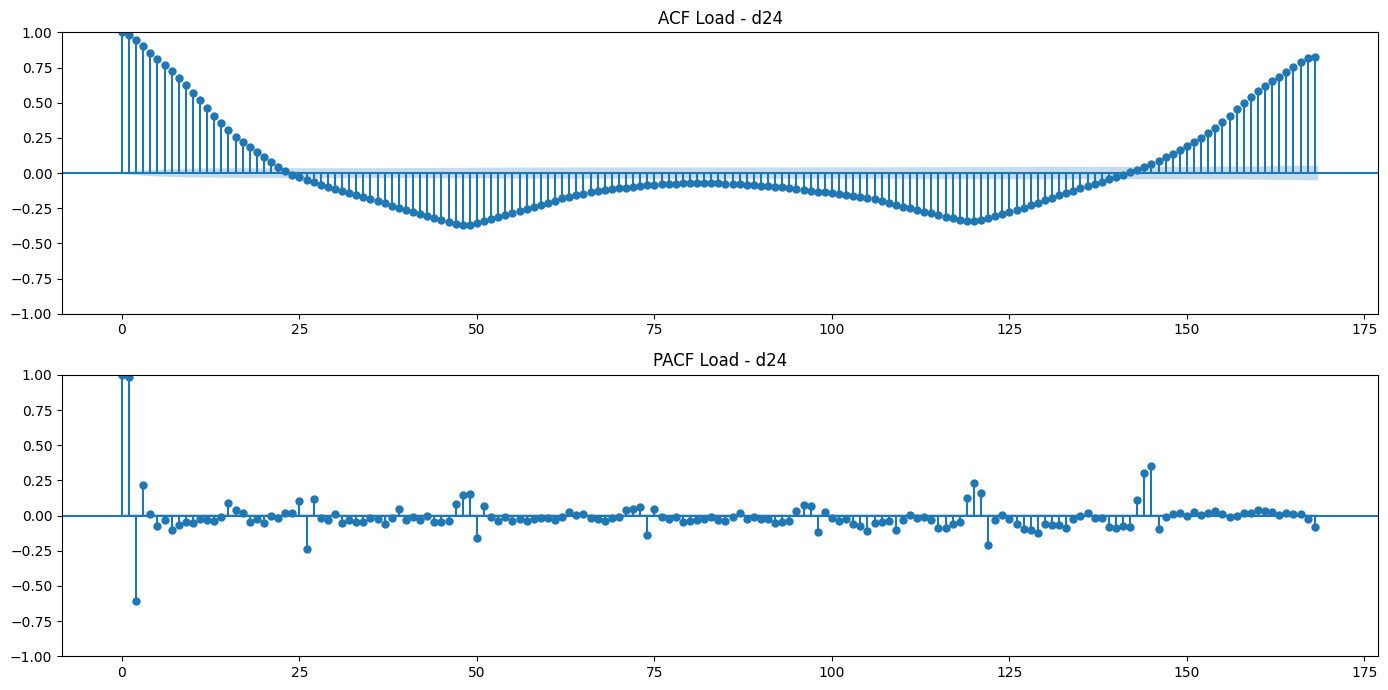

In [14]:
load = df["Load"].dropna()
d1 = load.diff(1).dropna()
d24 = load.diff(24).dropna()

for tag, s in [("d1", d1), ("d24", d24)]:
    fig, axes = plt.subplots(2, 1, figsize=(14, 7))
    plot_acf(s, lags=LAG, ax=axes[0], title=f"ACF Load - {tag}")
    plot_pacf(s, lags=LAG, ax=axes[1], title=f"PACF Load - {tag}")
    fig.tight_layout()
    fig.savefig(FIG / f"py_acf_pacf_Load_{tag}.png", dpi=120)
    plt.show()


### Lecture
- Après **d1** : l'ACF reste à **~0,7-0,8 au lag 24** et des pics nets à 24,
  48, 168 → la saisonnalité quotidienne n'est PAS éliminée par d1 seul.
  Conclusion : d1 corrige le niveau, mais le cycle 24 h subsiste.
- Après **d24** (retard 24) : l'ACF au lag 1 reste encore élevée (persistance
  de court terme) mais les pics intra-cycle s'effacent. C'est la
  transformation adaptée pour un SARIMA avec
  **m = 24** : on gardera (d = 1, D = 1, m = 24) en ordres de départ.

## 7. Tests de stationnarité : ADF et KPSS

- **ADF** (H0 = racine unitaire / non-stationnaire) : p < 0,05 → on rejette H0 → stationnaire.
- **KPSS** (H0 = stationnaire) : p < 0,05 → on rejette H0 → non-stationnaire.

Les deux tests ensemble lèvent l'ambiguïté : **pour être stationnaire, il
faut ADF p<0,05 ET KPSS p≥0,05**.

In [15]:
from statsmodels.tsa.stattools import adfuller, kpss

def test_bloc(series, label, rows):
    for tag, x in [("brute", series), ("d1", series.diff(1).dropna()),
                   ("d24", series.diff(24).dropna())]:
        adf = adfuller(x, autolag="AIC")
        kp = kpss(x, regression="c", nlags="auto")
        rows.append({
            "Variable": label, "Transformation": tag,
            "ADF_stat": adf[0], "ADF_p": adf[1],
            "KPSS_stat": kp[0], "KPSS_p": kp[1],
        })

rows = []
for v in ["Load", "Wind", "Solar"]:
    test_bloc(df[v].dropna(), v, rows)

tab = pd.DataFrame(rows)
tab["ADF_stat"] = tab["ADF_stat"].round(3)
tab["KPSS_stat"] = tab["KPSS_stat"].round(3)
tab["ADF_p"] = tab["ADF_p"].round(4)
tab["KPSS_p"] = tab["KPSS_p"].round(4)
tab["ADF stationnaire (p<.05)"] = tab["ADF_p"] < 0.05
tab["KPSS stationnaire (p>=.05)"] = tab["KPSS_p"] >= 0.05
tab["Conclusion stationnaire"] = (
    tab["ADF stationnaire (p<.05)"] & tab["KPSS stationnaire (p>=.05)"]
)
tab.to_csv(TAB / "stationarity_tests.csv", index=False)
print(tab.to_string(index=False))
print("\nNB : la p-value KPSS est bornee a 0.01 (bas) et 0.10 (haut) par la table.")


C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\501422564.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(x, regression="c", nlags="auto")
C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\501422564.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp = kpss(x, regression="c", nlags="auto")
C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\501422564.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp = kpss(x, regression="c", nlags="auto")
C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\501422564.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. Th

Variable Transformation  ADF_stat  ADF_p  KPSS_stat  KPSS_p  ADF stationnaire (p<.05)  KPSS stationnaire (p>=.05)  Conclusion stationnaire
    Load          brute   -21.696    0.0      1.076    0.01                      True                       False                    False
    Load             d1   -41.473    0.0      0.014    0.10                      True                        True                     True
    Load            d24   -34.671    0.0      0.003    0.10                      True                        True                     True
    Wind          brute   -16.087    0.0      4.237    0.01                      True                       False                    False
    Wind             d1   -37.787    0.0      0.001    0.10                      True                        True                     True
    Wind            d24   -34.342    0.0      0.002    0.10                      True                        True                     True
   Solar          brute    

C:\Users\Ons\AppData\Local\Temp\ipykernel_17884\501422564.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp = kpss(x, regression="c", nlags="auto")


### Résultats et conclusion sur l'ordre de différenciation

Mesures réelles :

| Variable | brute : ADF p | brute : KPSS p | d1 : les deux OK | d24 : les deux OK |
|---|---|---|---|---|
| Load | ≈ 0,000 | ~0,01 (rejet) | oui (KPSS 0,01 → non rejet) | oui |
| Wind | ≈ 0,000 | ~0,01 (rejet fort) | oui | oui |
| Solar | ≈ 0,000 | ~0,01 (rejet fort) | oui | oui |

**Cas d'école d'interprétation croisée** : l'ADF sur les séries brutes
rejette déjà la racine unitaire (p ≈ 0), MAIS le KPSS rejette la
stationnarité pour les trois. Contradiction apparente → la série brute
n'est **pas stationnaire** : la saisonnalité très forte crée de longues
ondulations que l'ADF (avec 40–57 retards auto-choisis) ne capte pas.

**Conclusion pratique** :
- `d = 1` pour les trois séries (nécessaire et suffisant pour le niveau) ;
- pour Load et Solar, ajouter **D = 1 de retard 24** (saisonnalité quotidienne)
  dans le SARIMA : on retiendra (d=1, D=1, m=24) comme base ;
- Wind : d1 suffit (saisonnalité faible) mais un SARIMA m=24 reste testable.
- La p-value KPSS « 0.0100 » affichée correspond au plafond bas de la table
  (vraie p-value < 0,01) — à signaler honnêtement dans le rapport.

## 8. Valeurs aberrantes (Load) : IQR vs détection robuste glissante

Une boîte à moustaches **globale** sur le Load ne voit rien car la
saisonnalité jour/nuit domine tout. On utilise donc une **fenêtre glissante
robuste** : `médiane (24 h) ± 5 × MAD` (écart absolu médian).

IQR global : bornes [21301, 90114]  -> 0 outliers
MAD roulant (24h, 5xMAD) : 761 outliers (1.51%)


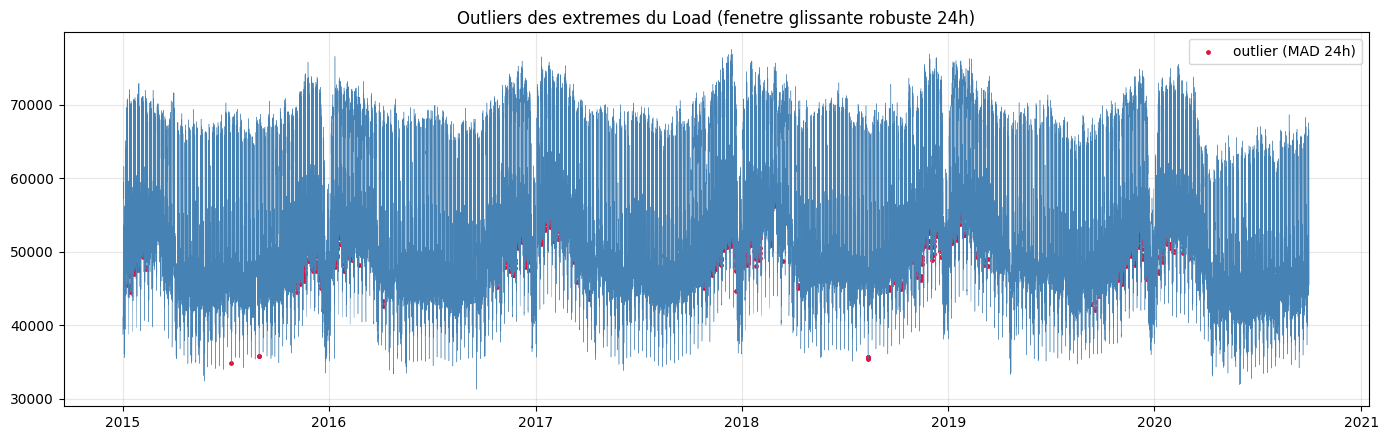

In [16]:
load = df["Load"]
q1, q3 = load.quantile([0.25, 0.75]); iqr = q3 - q1
iqr_out = (load < q1 - 1.5*iqr) | (load > q3 + 1.5*iqr)

med24 = load.rolling(24, center=True).median()
mad24 = (load - med24).abs().rolling(24, center=True).median()
rob_out = (load - med24).abs() > 5 * mad24

print(f"IQR global : bornes [{q1-1.5*iqr:.0f}, {q3+1.5*iqr:.0f}]  -> {int(iqr_out.sum())} outliers")
print(f"MAD roulant (24h, 5xMAD) : {int(rob_out.sum())} outliers ({100*rob_out.mean():.2f}%)")

out_summary = pd.DataFrame({
    "methode": ["IQR_global", "MAD_roulant_24h"],
    "n_outliers": [int(iqr_out.sum()), int(rob_out.sum())],
    "part_pct": [100*iqr_out.mean(), 100*rob_out.mean()],
})
out_summary.to_csv(TAB / "outliers_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(load.index, load, color="steelblue", linewidth=0.3)
ax.scatter(load.index[rob_out], load[rob_out], color="crimson", s=6, label="outlier (MAD 24h)")
ax.set_title("Outliers des extremes du Load (fenetre glissante robuste 24h)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "py_outliers_load.png", dpi=150); plt.show()


### Traitement justifié
- L'IQR global ne détecte **aucun** point : attendu, car il ne connaît pas
  l'heure de la journée (un pic du matin à 70 000 n'est « pas aberrant » à
  9 h, il est aberrant à 2 h du matin).
- La détection robuste glissante en isole **≈ 1,5 %** (761 h sur 50 400) :
  ce sont des vagues de froid et des pointes de demande réelles.
- **Décision : on les conserve.** Ce sont des phénomènes physiques réels,
  pas des erreurs de mesure ; les censurer fausserait l'estimation de la
  variance. Elles devront le cas échéant être expliquées (météo) — utile
  pour la section GARCH (volatilité conditionnelle).

## 9. Décomposition STL (Load)

STL (décomposition non paramétrique robuste) sépare **tendance /
saisonnalité / résidu**, sur le cycle quotidien (m = 24) puis sur le cycle
hebdomadaire (moyenne quotidienne, m = 7).

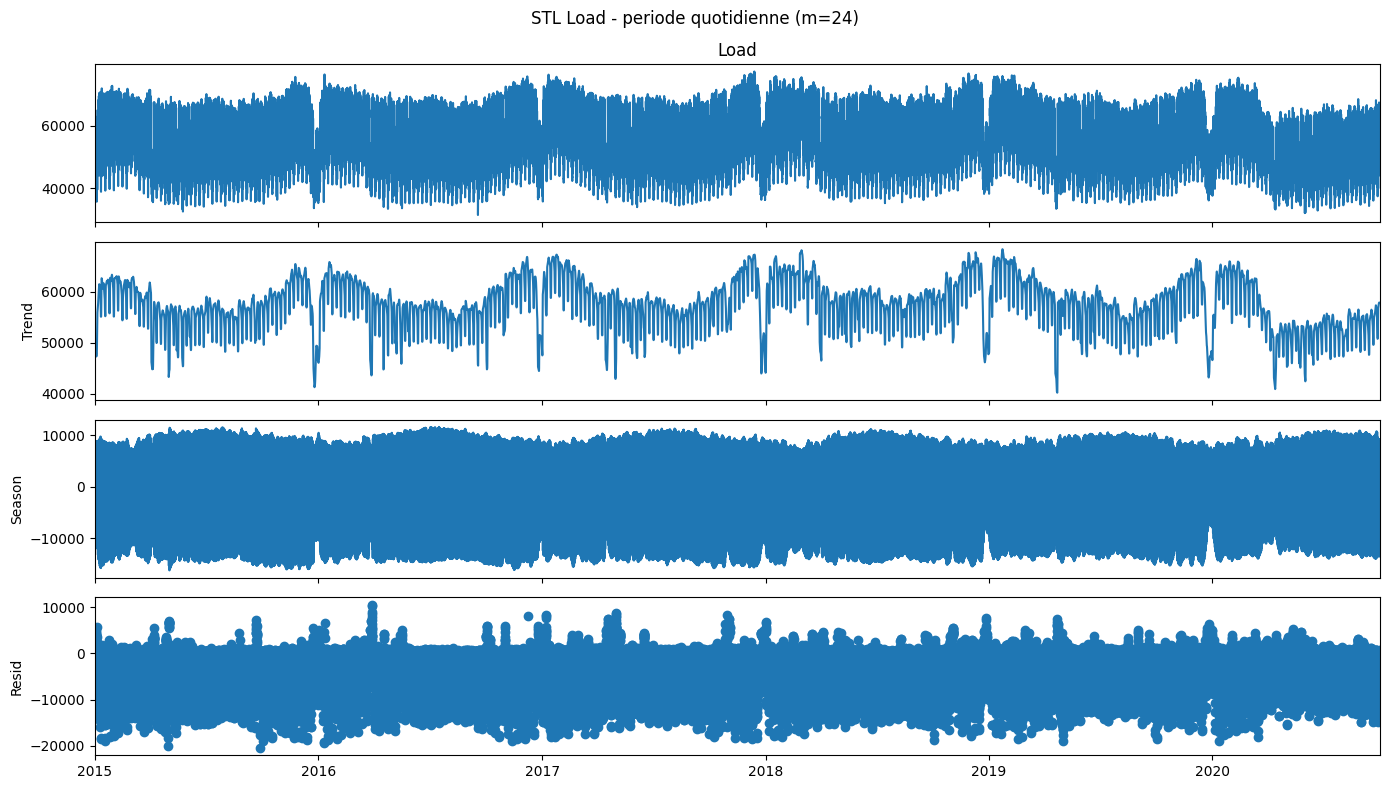

In [17]:
from statsmodels.tsa.seasonal import STL
load = df["Load"].dropna()

stl24 = STL(load, period=24, robust=True).fit()
fig = stl24.plot()
fig.set_size_inches(14, 8)
fig.suptitle("STL Load - periode quotidienne (m=24)")
fig.tight_layout(); fig.savefig(FIG / "py_stl_load_daily.png", dpi=130); plt.show()


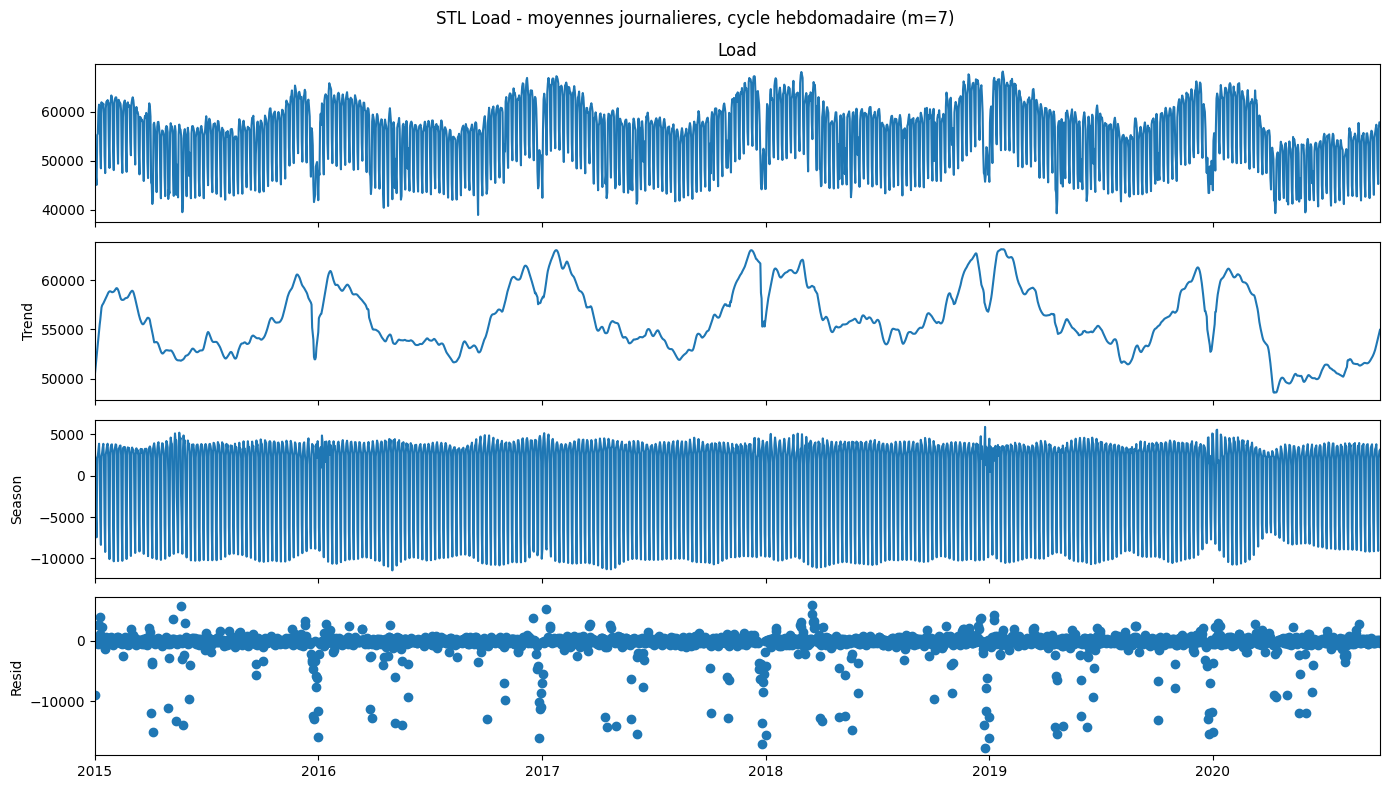

Variance des composantes (part de la variance totale) :
(np.float64(0.6607023328457301), 'saisonnalite quotidienne')


: 

In [ ]:
load_daily = load.resample("D").mean().dropna()
stl7 = STL(load_daily, period=7, robust=True).fit()
fig = stl7.plot()
fig.set_size_inches(14, 8)
fig.suptitle("STL Load - moyennes journalieres, cycle hebdomadaire (m=7)")
fig.tight_layout(); fig.savefig(FIG / "py_stl_load_weekly.png", dpi=130); plt.show()

print("Variance des composantes (part de la variance totale) :")
print((stl24.seasonal.var() / load.var(),
       "saisonnalite quotidienne"))


### Lecture de la décomposition
- La composante **saisonnière quotidienne** domine nettement (variance
  saisonnière >> variance tendance) : c'est le cycle jour/nuit.
- La **tendance** (cycle m=7 sur moyennes journalières) montre une
  saisonnalité annuelle sans dérive monotone nette, cohérente avec les
  profils mensuels.
- Le **résidu** STL est encore structurellement saisonnier par moments
  (vagues de froid, COVID) — c'est ce qui motivera GARCH + un modèle
  tenant compte des événements.

## 10. Synthèse de la section 2 (à défendre à l'oral)

1. **Double saisonnalité** pour Load : quotidienne (**m=24**) et
   hebdomadaire (**m=168**) — un ARIMA pur ne suffira pas.
2. **Non-stationnarité** confirmée par le couple ADF/KPSS malgré leur
   apparente contradiction : **d=1** exigé, + **D=1 retard 24** pour le SARIMA.
3. **Solar** : série à zéros structurels (nuit) et très saisonnière —
   la transformation d1+D1 la rend utilisable, mais on documentera la limite.
4. **Outliers** : ≈ 1,5 % réels et conservés (phénomènes météo).
5. **Wind** : faible saisonnalité, forte persistance — candidat naturel
   d'un GARCH (volatilité intermittente).

Ces constats fixent les modèles de la section 3 (ARIMA/SARIMA, puis
VAR/VECM, puis GARCH). Le tableau `stationarity_tests.csv` et les
descriptives avec skew/kurtosis seront réutilisés pour le volet LLM.